Name: Keerthi N

Registration No: 2411021240024

University: Alliance University

Subject: Deep Learning

Topic: Simple Neural Network Forward Propagation

# Objective

To understand how forward propagation works in a simple neural network using the Iris dataset. The project uses input features, weights, biases, and activation functions to generate predictions for three species of Iris flowers.


# Introduction

A neural network is a machine learning model inspired by the human brain. It consists of layers of connected neurons that process input data.

Forward propagation is the process of passing input data through the network to produce an output. In this project, we use the Iris dataset to understand how a neural network classifies flowers into different species.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

# Task 1: Load and Prepare the Iris Dataset

The Iris dataset contains measurements of flowers from three species. It has four input features and one target class.


In [ ]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Features:", iris.feature_names)
print("Classes:", iris.target_names)

Dataset shape: (150, 4)
Target shape: (150,)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']


In [ ]:
df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = iris.target_names[y]

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


# Data Preprocessing

The dataset is divided into training and testing data. Standardization scales the input features so that they have comparable ranges, helping the neural network process them.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


# Task 2: Build a Simple Neural Network

The neural network has three layers:

* Input layer: 4 neurons representing the four Iris features.
* Hidden layer: 5 neurons that learn combinations of input features.
* Output layer: 3 neurons representing the three flower species.

Each neuron calculates a weighted sum of its inputs, adds a bias, and applies an activation function.


# Activation Functions

An activation function determines how a neuron transforms its calculated input.

* ReLU: Changes negative values to zero and keeps positive values unchanged.
* Softmax: Converts output scores into probabilities that sum to 1.


In [ ]:
def relu(x):
    return np.maximum(0, x)

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

print("ReLU:", relu(np.array([-2, 0, 3])))
print("Softmax:", softmax(np.array([[2.0, 1.0, 0.5]])))

ReLU: [0 0 3]
Softmax: [[0.62853172 0.2312239  0.14024438]]


# Initialize Weights and Biases

Weights control the influence of each input on a neuron. Biases allow the neuron to shift its output. We initialize them with small random values so that the neurons do not all start with identical parameters.


In [ ]:
np.random.seed(42)

W1 = np.random.randn(4, 5) * 0.1
b1 = np.zeros((1, 5))

W2 = np.random.randn(5, 3) * 0.1
b2 = np.zeros((1, 3))

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

W1 shape: (4, 5)
b1 shape: (1, 5)
W2 shape: (5, 3)
b2 shape: (1, 3)


# Forward Propagation

Forward propagation passes the input data through the neural network.

The calculations are:

1. Hidden layer: \(Z_1 = XW_1+b_1\)
2. Apply ReLU: \(A_1 = ReLU(Z_1)\)
3. Output layer: \(Z_2 = A_1W_2+b_2\)
4. Apply Softmax: \(A_2 = Softmax(Z_2)\)

The final output contains the predicted probability for each flower species.


In [ ]:
def forward_propagation(X):
    Z1 = np.dot(X, W1) + b1
    A1 = relu(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = softmax(Z2)

    return A1, A2

A1, predictions = forward_propagation(X_test)

print("Hidden layer output:")
print(A1[:3])

print("\nOutput probabilities:")
print(predictions[:3])

Hidden layer output:
[[0.0564216  0.20605829 0.         0.1313753  0.46324699]
 [0.         0.         0.05182005 0.         0.        ]
 [0.00567561 0.         0.         0.         0.03173004]]

Output probabilities:
[[0.32765548 0.31359877 0.35874575]
 [0.33213778 0.33477585 0.33308637]
 [0.33360057 0.33217804 0.33422139]]


# Task 3: Apply Activation Function and Display Predictions

The Softmax output gives a probability for each of the three species. The species with the highest probability is selected as the predicted class using argmax.


In [ ]:
y_pred = np.argmax(predictions, axis=1)

results = pd.DataFrame({
    "Actual": iris.target_names[y_test],
    "Predicted": iris.target_names[y_pred]
})

print(results.head(10))

       Actual   Predicted
0      setosa   virginica
1   virginica  versicolor
2  versicolor   virginica
3  versicolor      setosa
4      setosa   virginica
5  versicolor  versicolor
6      setosa   virginica
7      setosa   virginica
8   virginica  versicolor
9  versicolor      setosa


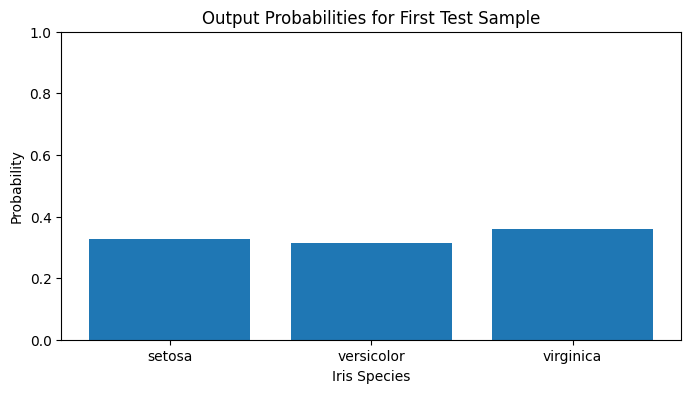

In [ ]:
plt.figure(figsize=(8, 4))

plt.bar(
    iris.target_names,
    predictions[0]
)

plt.title("Output Probabilities for First Test Sample")
plt.xlabel("Iris Species")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.show()

# Understanding the Output

The neural network calculates a score for each flower species. Softmax converts these scores into probabilities. The class with the highest probability becomes the predicted output.

Since the network uses randomly initialized weights without training, the predicted species may not match the actual species. This project demonstrates forward propagation rather than a fully trained classifier.


# Conclusion

In this project, a simple neural network was created using the Iris dataset. The data was loaded, split, and standardized. We initialized weights and biases, performed forward propagation, and applied ReLU and Softmax activation functions to generate classification predictions.

The project helped demonstrate how input data moves through a neural network and how output probabilities are used to select a predicted class.
